# Exercise Sheet 4

## Part 1: Gaussian Process Regression and Kernels with GPyTorch and BoTorch

### Library Loading Block

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Wednesday September 23, 2026

@authors: Elena Raponi, Iván Olarte Rodríguez

"""

# Import the Libraries

# Typical Libraries for Numerical Processing
import numpy as np
import torch

### NOTE: It's important to import Torch before Matplotlib, otherwise you will get a warning message about the backend of Matplotlib or 
###       other issues
from matplotlib import pyplot as plt

# Import some botorch test functions
from botorch.test_functions.synthetic import (Ackley as AckleyBOTorch, Rosenbrock as RosenbrockBOTorch)

# Import the BoTorch SingleTaskGP model and the ExactMarginalLogLikelihood for training the GP model
from botorch.models import SingleTaskGP
from botorch.models.transforms import Standardize

from gpytorch.likelihoods import FixedNoiseGaussianLikelihood
from gpytorch.constraints import Interval
from gpytorch.kernels import MaternKernel, ScaleKernel, RBFKernel, Kernel as GPyTorchKernel
from gpytorch.means import ConstantMean, Mean as GPyTorchMean

from typing import Callable, Optional, Tuple, Union
import pyDOE2
from scipy.stats.qmc import scale

**The following block is just a helper**. Just Run it!

In [157]:
def process_ndarray_torch_input(input_array: Union[np.ndarray, torch.Tensor]) -> torch.Tensor:
    """
    Process the input array to ensure it is a 2D torch tensor.

    Parameters
    ----------
    input_array : Union[np.ndarray, torch.Tensor]
        The input array to be processed.

    Returns
    -------
    torch.Tensor
        A 2D torch tensor.
    """
    if isinstance(input_array, np.ndarray):
        input_array = torch.from_numpy(input_array).reshape(-1, 1).to(torch.float64)

    if isinstance(input_array, torch.Tensor):
        input_array = input_array.detach().clone().reshape(-1, 1).to(torch.float64)
    
    if not isinstance(input_array, torch.Tensor):
        raise TypeError("Input must be a numpy array or a torch tensor.")
    
    
    return input_array

def check_output_type(output_type: str) -> None:
    """
    Check if the output type is valid.

    Parameters
    ----------
    output_type : str
        The output type to be checked.

    Raises
    ------
    ValueError
        If the output type is not 'numpy' or 'torch'.
    """
    if output_type not in ['numpy', 'torch']:
        raise ValueError("output_type must be either 'numpy' or 'torch'.")

In the following block there are listed four different functions. Run this block in order to load the functions into the main module. These functions are then going to be switched to perform different approximations with the regressors.

In [158]:
def f(X:Union[np.ndarray, torch.Tensor],
      output_type: Optional[str] = "numpy")->Union[np.ndarray, torch.Tensor]:
    r"""
    This is a simple test function that can be used to test the performance of the Gaussian Process Regression (GPR) model. 
    The function is defined as: $$f(x) = x \cdot \cos(x) + 10$$.

    Args:
        X (Union[np.ndarray, torch.Tensor]): Input array or tensor of shape (n_samples,1) 
        containing the input values for which the function will be evaluated.
        output_type (Optional[str]): Specifies the desired output type.
            - 'numpy': Returns the output as a numpy array.
            - 'torch': Returns the output as a PyTorch tensor.
    
    Returns:
        Union[np.ndarray, torch.Tensor]: The value of the function at the given point.
    """

    x = process_ndarray_torch_input(X)
    check_output_type(output_type)
    
    if output_type == 'numpy':
        return torch.mul(x, torch.cos(x)).detach().cpu().numpy() + 10
    else:
        return torch.mul(x, torch.cos(x)) + 10

def Ackley(x1:Union[np.ndarray, torch.Tensor],
           x2:Union[np.ndarray, torch.Tensor],
           output_type: Optional[str] = "numpy")->Union[np.ndarray, torch.Tensor]:
    r"""
    Ackley function is a common test function for optimization algorithms.
    It is defined as:
    $$f(x1, x2) = -20 \exp(-0.2 \sqrt{0.5 (x1^2 + x2^2)}) - \exp(0.5 (\cos(2 \pi x1) + \cos(2 \pi x2))) + 20 + e$$

    Args:
        x1 (Union[np.ndarray, torch.Tensor]): Input array or tensor of shape (n_samples, 1)
        containing the first input values for which the function will be evaluated.
        x2 (Union[np.ndarray, torch.Tensor]): Input array or tensor of shape (n_samples, 1)
        containing the second input values for which the function will be evaluated.
        output_type (Optional[str]): Specifies the desired output type.
            - 'numpy': Returns the output as a numpy array.
            - 'torch': Returns the output as a PyTorch tensor.

    Returns:
        Union[np.ndarray, torch.Tensor]: The value of the Ackley function at the given point.
    """

    x1_t = process_ndarray_torch_input(x1)
    x2_t = process_ndarray_torch_input(x2)

    check_output_type(output_type)

    x = torch.column_stack((x1_t, x2_t))

    # Call the Ackley function formula
    ackley_fun = AckleyBOTorch(dim=2, bounds=[(-5, 5), (-5, 5)])

    if output_type == "numpy":
        return ackley_fun(x).detach().cpu().numpy()
    else:
        return ackley_fun(x)

def Rosenbrock(x1:Union[np.ndarray, torch.Tensor], x2:Union[np.ndarray, torch.Tensor],
               output_type: Optional[str] = "numpy")->Union[np.ndarray, torch.Tensor]: 
    """
    Rosenbrock function is a common test function for optimization algorithms.
        It is defined as:
        $$f(x1, x2) = (a - x1)^2 + b(x2 - x1^2)^2$$ with a = 1 and b = 100.
    
        Args:
            x1 (Union[np.ndarray, torch.Tensor]): Input array or tensor of shape (n_samples, 1)
            containing the first input values for which the function will be evaluated.
            x2 (Union[np.ndarray, torch.Tensor]): Input array or tensor of shape (n_samples, 1)
            containing the second input values for which the function will be evaluated.
            output_type (Optional[str]): Specifies the desired output type.
                - 'numpy': Returns the output as a numpy array.
                - 'torch': Returns the output as a PyTorch tensor.
    
        Returns:
            Union[np.ndarray, torch.Tensor]: The value of the Rosenbrock function at the given point.
    """

    x1_t = process_ndarray_torch_input(x1)
    x2_t = process_ndarray_torch_input(x2)

    check_output_type(output_type)

    x = torch.column_stack((x1_t, x2_t))

    # Call the Rosenbrock function formula
    rosenbrock_fun = RosenbrockBOTorch(dim=2, bounds=[(-5, 5), (-5, 5)])

    if output_type == "numpy":
        return rosenbrock_fun(x).detach().cpu().numpy()
    else:
        return rosenbrock_fun(x)

def Sphere(
    x1: Union[np.ndarray, torch.Tensor],
    x2: Union[np.ndarray, torch.Tensor],
    output_type: str = "numpy",
) -> Union[np.ndarray, torch.Tensor]:
    """
    Evaluate f(x1, x2) = x1^2 + x2^2 for each sample.

    Args:
        x1 (Union[np.ndarray, torch.Tensor]): Input array or tensor of shape (n_samples, 1) containing the first input values for which the function will be evaluated.
        x2 (Union[np.ndarray, torch.Tensor]): Input array or tensor of shape (n_samples, 1) containing the second input values for which the function will be evaluated.
        output_type (str): Specifies the desired output type. Can be either 'numpy' or 'torch'.
    """

    x1_t = process_ndarray_torch_input(x1)
    x2_t = process_ndarray_torch_input(x2)

    check_output_type(output_type)

    if x1_t.ndim != 2 or x1_t.shape[1] != 1 or x1_t.shape != x2_t.shape:
        raise ValueError("x1 and x2 must have matching shapes (n_samples, 1).")

    result = torch.sum(torch.cat((x1_t, x2_t), dim=1) ** 2, dim=1, keepdim=False)

    if output_type == "numpy":
        return result.detach().cpu().numpy()
    return result


Run the following block to plot the implementation of the interpolation

In [159]:
# define our known points and their measurements
# We start with a 1D simple example
# Sampling locations
xi = np.atleast_2d([-3., -1, 1.5, 2.5, 3]).T

# Sample observations
fi = f(xi).ravel()

# Some length scale
L= 1.0

The following block is a helper block to generate plotting functions. These are meant to plot the function, the prediction and the 95% confidence interval based on the mean squared error.

In [160]:
def plot_results_2d(X_obs:np.ndarray, y_obs:np.ndarray, x_:np.ndarray, y_pred:np.ndarray, sigma:np.ndarray,
                    eval_fun:Callable[[Union[np.ndarray, torch.Tensor]], Union[np.ndarray, torch.Tensor]]=f,
                    fun_label=r'$f(x) = x\ cos(x) + 10$'):
    plt.figure()
    plt.plot(x_, eval_fun(x_), 'r:', label=fun_label)
    plt.plot(X_obs, y_obs, 'r.', markersize=10, label='Observations')
    plt.plot(x_, y_pred, 'k-', label='Prediction')
    plt.fill(np.concatenate([x_, x_[::-1]]),
             np.concatenate([y_pred - 1.9600 * sigma,
                            (y_pred + 1.9600 * sigma)[::-1]]),
             alpha=.3, fc='k', label=r'95% confidence interval')
    plt.xlabel('$x$')
    plt.ylabel('$f(x)$')
    plt.ylim(0, 25)
    plt.legend(loc='upper right', bbox_to_anchor=(1.5, 1))
    plt.show()


def plot_results_2d_GPTorch(
    X_obs: np.ndarray,
    y_obs: np.ndarray,
    x_: np.ndarray,
    model: SingleTaskGP,
    eval_fun: Callable = f,
    dtype=torch.float64,
    device=torch.device("cpu"),
    fun_label=r"$f(x) = x\cos(x) + 10$",
):
    fig, ax = plt.subplots()

    x_plot = np.asarray(x_).reshape(-1)

    with torch.no_grad():
        x_tensor = torch.as_tensor(x_, dtype=dtype, device=device)
        posterior = model.posterior(x_tensor)
        lower, upper = posterior.mvn.confidence_region()

        true_y = eval_fun(x_)
        if isinstance(true_y, torch.Tensor):
            true_y = true_y.detach().cpu().numpy()

        ax.plot(x_plot, np.asarray(true_y).reshape(-1), "r:", label=fun_label)
        ax.plot(np.asarray(X_obs).reshape(-1),
                np.asarray(y_obs).reshape(-1), "r.", label="Observations")
        ax.plot(x_plot, posterior.mean.cpu().numpy().reshape(-1), "k-",
                label="Posterior mean")
        ax.fill_between(
            x_plot,
            lower.cpu().numpy().reshape(-1),
            upper.cpu().numpy().reshape(-1),
            alpha=0.3,
            color="k",
            label="95% confidence interval",
        )

    ax.set_xlabel("$x$")
    ax.set_ylabel("$f(x)$")
    ax.set_ylim(0, 25)
    ax.legend(loc="upper right", bbox_to_anchor=(1.5, 1))
    plt.show()
    
def plot_doe(x, lb = 0.0, ub = 1.0):
    num_samp = np.size(x,0)
    num_sampf = float(num_samp)
    fig = plt.figure()
    ax = fig.gca()
    ax.scatter(x[:,0],x[:,1])
    # --- boundaries of the design space
    ax.plot([0,0,1,1,0],[0,1,1,0,0], color=[0.5,0.5,0.5], linestyle='--', linewidth = 0.5)
    # --- grid lines  
    for i in range(num_samp):
        tmp = lb + (ub-lb)*i/num_sampf
        ax.plot([lb,ub],[tmp,tmp],color=[0.5,0.5,0.5], linestyle=':')
        ax.plot([tmp,tmp],[lb,ub],color=[0.5,0.5,0.5], linestyle=':')
        
    ax.set_xlim(lb,ub)
    ax.set_ylim(lb,ub)
    # -- labels
    ax.set_xlabel('x1', labelpad=8)
    ax.set_ylabel('x2', labelpad=8)
    plt.title('Optimal LH Samples', fontsize = 12)
    plt.axis('square')
    
def plot_results_3d(x1, x2, y_pred, x_samp=None, y_samp=None, lb=0.0, ub=1.0, title = '3D surface plot'):
    
    plt.figure(figsize=(15,10))

    fig,ax = plt.subplots(subplot_kw={"projection": "3d"})
    ax.plot_surface(x1, x2, y_pred, cmap='coolwarm', alpha = 0.6)
    if x_samp is not None:
        ax.scatter(x_samp[:,0], x_samp[:,1], y_samp, c='r', marker='x')
    ax.set_xlim(lb,ub)
    ax.set_ylim(lb,ub)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_zlabel('Obj. Function')
    ax.set_title(title)

    

### Exercise 1: Gaussian Process Regression (with `GPyTorch`)
Fit the gaussian process regression (GPR) model using class `SingleTaskGP`. Sample points and kernel definition are given. Define all the input parameters required by `plot_results_2d_GPTorch`.

In the following setting, the final model is obtained by using numerical optimization techniques to maximize the likelihood of the observed data, given our GPR model. Set the number of restarts for the optimizer to 10. Furthermore, in the following block you may find the definition of two kernels from `GPyTorch`, namely a composite kernel comprising a RBF and a constant kernel and a Matérn kernel. In addition to this, try changing the length scale.

c:\Users\iolar\.conda\envs\bo-course\Lib\site-packages\gpytorch\likelihoods\noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 0.0001.
  warnings.warn(


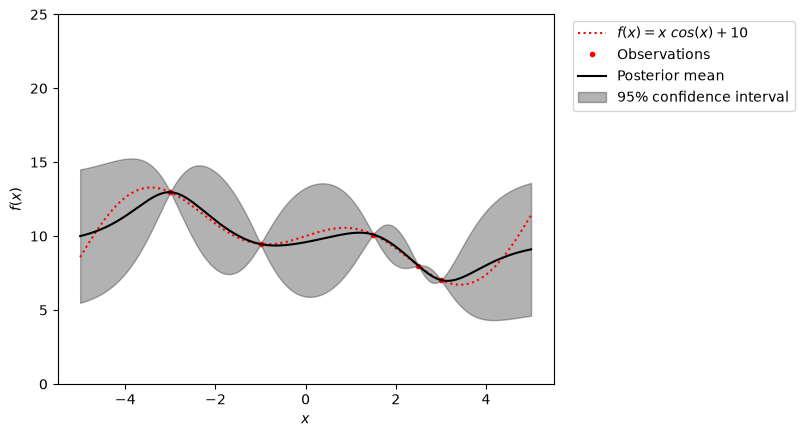

In [ ]:
# We start with a 1D simple example
# Sampling locations
X:np.ndarray = xi.copy()

# Sample observations
y = fi.copy()

# Mesh the input space for evaluations of the real function, the prediction and confidence interval
x = np.atleast_2d(np.linspace(-5, 5, 1000)).T

# Initiatlize a Gaussian Process model

##### TODO: In this part switch between the following defined kernels. Evaluate the results by switching each of them
kernel = ScaleKernel(MaternKernel(nu=1.5))
#kernel = ScaleKernel(RBFKernel())


#####--------------- END OF SWITCH -----------------------

##### TODO: Enter your code here:

#NOTE: The noise-free variance is set to a very small value (1e-5) to simulate a nearly noise-free scenario.
# This is an implementation detail to ensure numerical stability in the Gaussian Process model, a
# s a true noise-free scenario can lead to singular covariance matrices. 
# By adding a small amount of noise, we can avoid these numerical issues while still effectively modeling the underlying function.

noisefree_variance = 0.00001
noises = torch.ones(len(y)) * noisefree_variance
noise_free_likelihood = FixedNoiseGaussianLikelihood(noise=noises)


gp = SingleTaskGP(
    train_X=torch.from_numpy(X).to(torch.float64),
    train_Y=torch.from_numpy(y).to(torch.float64).unsqueeze(-1),
    covar_module=kernel,
    #input_transform=Normalize(d=1, bounds=torch.tensor([[-5.0], [5.0]]),transform_on_train=True, transform_on_eval=True),
    outcome_transform=Standardize(m=1),
    likelihood=noise_free_likelihood,
    mean_module=ConstantMean(),
)



# Set the hyperparameters of the kernel. 
gp.covar_module.base_kernel.nu = 2.5

# It determines the length scale of the output.
gp.covar_module.base_kernel.lengthscale = 1.

# model.covar_module.outputscale is what we call alpha0 
# (NOTE: For GPyTorch, the outputscale shall be used with the ScaleKernel decorator.)
gp.covar_module.outputscale = 1.0

# Set the hyperparameters of the mean
gp.mean_module.constant =  torch.tensor(0.)

##### --------------- END OF CODE INPUT -----------------------

gp.eval()
plot_results_2d_GPTorch(X_obs=X, y_obs=y, x_=x, model=gp, eval_fun=f, fun_label=r'$f(x) = x\ cos(x) + 10$')

### Exercise #2: Two-dimensional Gaussian Process Regression
Bring all your knowledge together and implement the whole process, from DoE to GPR regression, in this 2D example, i.e. we work with 2 variables and fit a response surface in a 3-dimensional space.

#### Steps
1. Sample the points. You can use the Latin Hypercube Sample generator from `PyDOE2` or use other sampling schemes.
2. Calculate the objective values at the corresponding sampled points
3. Call a kernel instance from `GPyTorch` and a Gaussian Process Regressor instance from the same library.
4. Fit the GP by using the points and corresponding objective values.
5. Use the GP to predict the values at unsampled points

c:\Users\iolar\.conda\envs\bo-course\Lib\site-packages\gpytorch\likelihoods\gaussian_likelihood.py:350: GPInputWarning: You have passed data through a FixedNoiseGaussianLikelihood that did not match the size of the fixed noise, *and* you did not specify noise. This is treated as a no-op.
  warnings.warn(


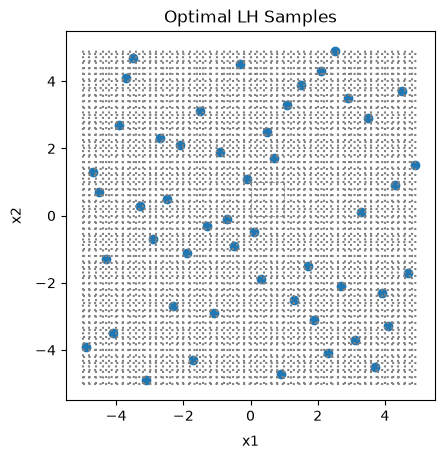

<Figure size 1500x1000 with 0 Axes>

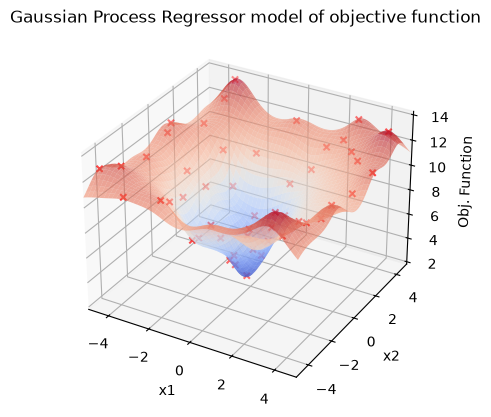

<Figure size 1500x1000 with 0 Axes>

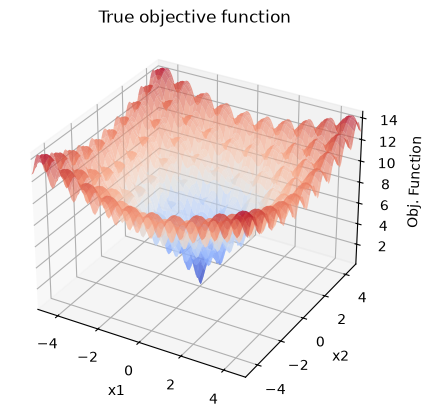

<Figure size 1500x1000 with 0 Axes>

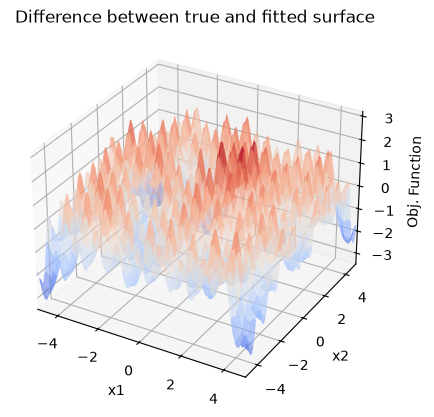

In [151]:
# Set parameters
g = Ackley # options are Sphere, Ackley, Rosenbrock
num_dv = 2
num_samp = 50  # Usually 10*[number of design variables] is a good rule of thumb
lb = -5
ub = 5

##### TODO: Enter your code here:

# Create samples using Optimal Latin Hypercube approach
x_samp = pyDOE2.lhs(num_dv, num_samp, criterion = 'centermaximin', iterations = 5000, random_state=43)
#x_samp = lb + (ub-lb)*x_samp  # We have to map the generated samples back to our design space
x_samp = scale(x_samp, [lb]*2, [ub]*2)  # We have to map the generated samples back to our design space
plot_doe(x_samp, lb, ub)

# Calculate objective function values
y_samp = g(x_samp[:,0], x_samp[:,1])

#Initiate Gaussian Process model
kernel = ScaleKernel(MaternKernel(nu=2.5),
                     outputscale=1.0,
                     outputscale_constraint=Interval(1e-5, 1e5))  # You can also try other kernels like RBFKernel, MaternKernel with different nu values, etc.


noisefree_variance = 0.00001
noises = torch.ones(len(y)) * noisefree_variance
noise_free_likelihood = FixedNoiseGaussianLikelihood(noise=noises)

gp = SingleTaskGP(
    train_X=torch.from_numpy(x_samp).to(torch.float64),
    train_Y=torch.from_numpy(y_samp).to(torch.float64).unsqueeze(-1),
    covar_module=kernel,
    outcome_transform=Standardize(m=1),
    likelihood=noise_free_likelihood,
    mean_module=ConstantMean(),
)

# Set the hyperparameters of the kernel. 
gp.covar_module.base_kernel.nu = 2.5

# It determines the length scale of the output.
gp.covar_module.base_kernel.lengthscale = L

# model.covar_module.outputscale is what we call alpha0 
# (NOTE: For GPYTorch, the outputscale shall be used with the ScaleKernel decorator.)
gp.covar_module.outputscale = 1.0

# Set the hyperparameters of the mean
gp.mean_module.constant =  torch.tensor(0.)



#Predict values on a meshed input space
x1_obs, x2_obs = np.meshgrid(np.linspace(lb,ub,100), np.linspace(lb,ub,100))
x_obs = np.array([np.reshape(x1_obs, (1,np.prod(x1_obs.shape)))[0], \
                    np.reshape(x2_obs, (1,np.prod(x2_obs.shape)))[0]]).T

# Set the model to evaluation mode and make predictions
gp.eval()
y_pred = gp.posterior(torch.from_numpy(x_obs).to(torch.float64)).mean.detach().cpu().numpy()
y_pred = np.reshape(y_pred, (100,100))

##### --------------- END OF CODE INPUT -----------------------

#Visualize results
plot_results_3d(x1_obs, x2_obs, y_pred, x_samp, y_samp, lb=lb, ub=ub,\
                title='Gaussian Process Regressor model of objective function')

#Also plot original function for comparison
plot_results_3d(x1_obs, x2_obs, g(x1_obs, x2_obs).reshape((100,100)), lb=lb, ub=ub,\
                title='True objective function')

#Finally get the difference between original and fitted surface
plot_results_3d(x1_obs, x2_obs, y_pred - g(x1_obs, x2_obs).reshape((100,100)), lb=lb, ub=ub,\
                title='Difference between true and fitted surface')

## Part 2: Setting up cases where there is no zero mean

### Exercise #3: Implement a Kernel Extension and predict functions
In the following blocks you're encouraged to generate your own tailormade Kernel and Predict functions. In the next block, you're encouraged to write a Matern Kernel yourself. For this, we will extend the _template_ kernel definition found in `GPyTorch`. In constrast to `scikit-learn`, here the length scale is something that is set a posteriori after initializing the object. Yet, the hyperparameter `nu` is required as in `scikit-learn` to compute the corresponding Bessel function.

In the following block implement the `__call__` function. The steps are commented as a hint.

Specifically, the Matern Kernel is defined as:

$$K(x,x^{\prime}|\alpha_{0},\nu) = \alpha_{0} \frac{2^{1-\nu}}{\Gamma(\nu)} \left(  \sqrt{2 \nu} \ d(x,x^{\prime})   \right)^{\nu} J_{(\nu)} \left(  \sqrt{2 \nu} \ d(x,x^{\prime})    \right)$$

Where $d(x,x^{\prime})$ is a distance metric between two points in the parameter space. Given that the space is finite dimensional, then this distance is normally the Euclidean distance (or __2-norm__) factored by a length scale $L$ as:

$$ d(x,x^{\prime})  = \frac{||x - x^{\prime} ||_{2}}{L}$$

On the other hand $\Gamma(\nu)$ represents the Gamma function evaluated at $\nu$. This function is evaluated via `scipy.special.gamma`. $J_{(\nu)}$ is the modified Bessel function of the second kind parameterized by $\nu$. This is evaluated via the function `scipy.special.kv`.

In [ ]:

from sklearn.gaussian_process.kernels import Kernel
from scipy.special import kv, gamma, kvp
import torch

# NOTE: The following implementation of the Bessel function is based on the SciPy library.
# Since the General Bessel function is not implemented in PyTorch, we use the SciPy implementation and wrap it 
# in a custom autograd function to enable gradient computation.

class ScipyBesselK(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x: torch.Tensor, nu: float) -> torch.Tensor:
        r"""
        Compute the modified Bessel function of the second kind, K_nu(x), for a given order nu and input x.
        
        """
        if torch.any(x <= 0):
            raise ValueError("Bessel K requires strictly positive x here.")

        ctx.save_for_backward(x)
        ctx.nu = nu

        values = kv(nu, x.detach().cpu().numpy())
        return torch.as_tensor(values, dtype=x.dtype, device=x.device)

    @staticmethod
    def backward(ctx, grad_output: torch.Tensor):
        (x,) = ctx.saved_tensors

        derivatives = kvp(ctx.nu, x.detach().cpu().numpy())
        derivatives = torch.as_tensor(
            derivatives, dtype=x.dtype, device=x.device
        )
        return grad_output * derivatives, None



class CustomMaternKernel(GPyTorchKernel):
    has_lengthscale = True
     
    def __init__(self, nu: float = 2.5,**kwargs):
        super().__init__(**kwargs)

        self.nu = nu

    def forward(self, x1: torch.Tensor, x2: torch.Tensor, diag: bool = False, **params) -> torch.Tensor:
        # Compute the pairwise distances
        if diag:
            distance = torch.abs(x1 - x2)
        else:
            distance = torch.cdist(x1, x2)

        # Override the distances if they are zero to avoid division by zero in the Bessel function
        distance = torch.where(distance == 0, torch.tensor(1e-9, dtype=distance.dtype, device=distance.device), distance)

        # Compute the Matern kernel using the Bessel function
        scale_factor = (2 ** (1 - self.nu)) / gamma(self.nu)
        sqrt_val = torch.sqrt(2 * torch.as_tensor(self.nu))
        inside_val = sqrt_val * distance / self.lengthscale
        bessel_values = ScipyBesselK.apply(inside_val, self.nu)
        matern_values = scale_factor * (inside_val) ** self.nu * bessel_values

        return matern_values
    
    

**RUN THE FOLLOWING BLOCK TO CHECK YOUR IMPLEMENTATION!** The matrices generated by the kernel from `GPyTorch` and the one you defined shall coincide!

In [178]:
# Call an instance of your customized kernel
kernel = CustomMaternKernel(nu=2.5)
kernel_def = MaternKernel(nu=2.5)

kernel.lengthscale = L
kernel_def.lengthscale = L

# Print a computation
X = torch.tensor([[1], [2], [3], [4]], dtype=torch.double)
X2 = torch.tensor([[2], [3], [4], [5]], dtype=torch.double)

kern_mat_1 = kernel(X,X2).detach().numpy()
kern_mat_2 = kernel_def(X,X2).detach().numpy()
print("Hard Coded Kernel: ", kern_mat_1)
print("Default Matern Kernel: ", kern_mat_2)
print("2-error norm: ", np.linalg.norm(kern_mat_1-kern_mat_2))


Hard Coded Kernel:  [[0.5239941  0.13866021 0.02772342 0.00477708]
 [1.         0.5239941  0.13866021 0.02772342]
 [0.5239941  1.         0.5239941  0.13866021]
 [0.13866021 0.5239941  1.         0.5239941 ]]
Default Matern Kernel:  [[0.52399411 0.13866022 0.02772342 0.00477708]
 [1.         0.52399411 0.13866022 0.02772342]
 [0.52399411 1.         0.52399411 0.13866022]
 [0.13866022 0.52399411 1.         0.52399411]]
2-error norm:  2.425615775930725e-08


Now run the following block to test your customized Kernel.

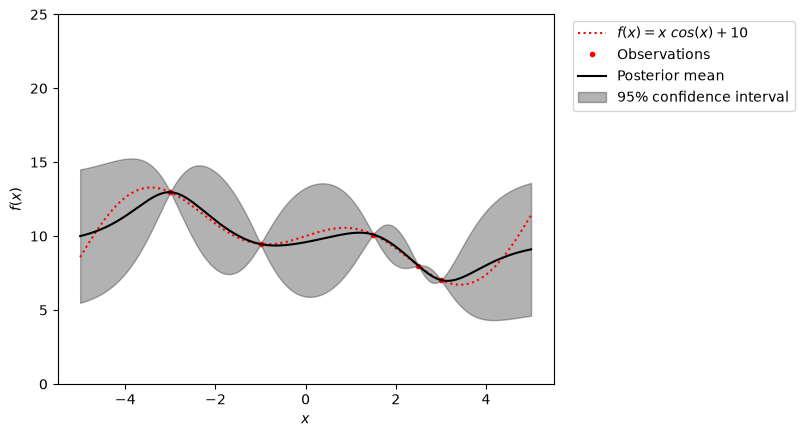

In [236]:
# We start with a 1D simple example
# Sampling locations
X:np.ndarray = xi.copy().reshape((-1, 1))


# Sample observations
y = fi.copy().reshape((-1, 1))

# Mesh the input space for evaluations of the real function, the prediction and confidence interval
x = np.atleast_2d(np.linspace(-5, 5, 1000)).reshape((-1, 1))

# Initialize a Gaussian Process model
kernel = CustomMaternKernel(nu=2.5)

gp = SingleTaskGP(
    train_X=torch.from_numpy(X).to(torch.float64),
    train_Y=torch.from_numpy(y).to(torch.float64),
    covar_module=kernel,
    likelihood=FixedNoiseGaussianLikelihood(noise=torch.ones(len(y)) * 1e-5),
    outcome_transform=Standardize(m=1),
    mean_module=ConstantMean(),
)

# Set the hyperparameters of the kernel. 
gp.covar_module.nu = 2.5

# It determines the length scale of the output.
gp.covar_module.lengthscale = 1.


# Set the hyperparameters of the mean
gp.mean_module.constant =  torch.tensor(0.)

gp.eval()
plot_results_2d_GPTorch(X_obs=X, y_obs=y, x_=x, model=gp, eval_fun=f, fun_label=r'$f(x) = x\ cos(x) + 10$')

Now it's turn to call a customized `fit_predict` function. Write a function that calculates the mean and variance of the 
posterior distribution at a point test_x. Your function should 
return the result as a list, where the first entry  is the posterior mean
and the second is the posterior variance.  You may find that because of 
numerical imprecision, the posterior variance can be slightly negative.

The mean and variance of the posterior distribution are defined as:
\begin{align}
f(x) &\mid f(x_{1:n}) \sim \mathrm{Normal}(\mu_n(x),\sigma^2_n(x))\\
\mu_n(x) &= \Sigma_0(x,x_{1:n}) \Sigma_0(x_{1:n},x_{1:n})^{-1} (f(x_{1:n})-\mu_0(x_{1:n})) + \mu_0(x) \\
\sigma^2_n(x) &= \Sigma_0(x,x) - \Sigma_0(x,x_{1:n}) \Sigma_0(x_{1:n},x_{1:n})^{-1} \Sigma_0(x_{1:n},x)
\end{align}


For the solution we suggest two linear algebra functions from `PyTorch`:
- torch.linalg.inv: https://docs.pytorch.org/docs/2.14/generated/torch.linalg.inv.html
- torch.matmul: https://docs.pytorch.org/docs/2.14/generated/torch.matmul.html

Also notice this time that the output from kernel and mean modules shall be transformed to `dense` matrices. `BoTorch` (and `GPyTorch`) have `LazyObjects` used for accelerating computations. This means that, for example, the kernel matrix is defined as a Sparse one. 

*Hint 1*: The formula in the BayesOpt tutorial has the expression,
$\Sigma_0(x_{1:n},x)$
which is a short way of writing the column vector,
$[\Sigma_0(x_1,x), \ldots, \Sigma_0(x_n,x)]^T$.

Suppose we have python code where:
* $\Sigma_0$ is computed by the function `kernel`
* $x_{1:n}$ is stored in the list `train_x`
* We have another point `x`

So then the row vector $\Sigma_0(x_{1:n},x)$ we want to construct is:

    [kernel(train_x[0],x),..., kernel(train_x[n-1],x))]

A quick way to construct this row vector as a list is 

    [kernel(y,x) for y in train_x]

*Hint 2:* You can convert a list of numbers to a `NumPy` array or `PyTorch` tensor. This allows for matrix multiplication, taking the transpose, and adding a subtracting scalars.

In [240]:
# This defines a mean function that evaluates to 0 for all inputs 
mean0 = ConstantMean()

# Use the custom Matern kernel with nu=2.5 and the standard Matern kernel with nu=2.5 for comparison
kern = ScaleKernel(CustomMaternKernel(nu=2.5))

# Use default Matern kernel with nu=2.5 from GPyTorch for comparison
kern_2 = ScaleKernel(MaternKernel(nu=2.5))

# Set the hyperparameters of the kernels
kern.base_kernel.lengthscale = torch.tensor(1.0)
kern.outputscale = torch.tensor(1.0)

kern_2.base_kernel.lengthscale = torch.tensor(1.0)
kern_2.outputscale = torch.tensor(1.0)

# Set the hyperparameters of the mean function
mean0.constant = torch.tensor(0.0)


def fit_predict(test_x, train_x, train_y, 
                kernel:GPyTorchKernel=kern, 
                mean:GPyTorchMean=mean0):
    r"""
    This function predicts the mean and variance of the Gaussian Process at a given test point using the provided training data and model.

    Args:
        test_x (Union[np.ndarray, torch.Tensor]): The test point(s) where predictions are to be made. Should be of shape (n_samples, n_features).
        train_x (Union[np.ndarray, torch.Tensor]): The training input data. Should be of shape (n_train_samples, n_features).
        train_y (Union[np.ndarray, torch.Tensor]): The training output data. Should be of shape (n_train_samples,).
        kernel (GPyTorchKernel): The kernel to use for the Gaussian Process.
        mean (GPyTorchMean): The mean function to use for the Gaussian Process.
    """

    def check_and_convert_to_tensor(data):
        if isinstance(data, (float, int)):
            return torch.tensor([[data]], dtype=torch.float64)
        elif isinstance(data, list):
            return torch.tensor(np.array(data).reshape((-1, 1)), dtype=torch.float64)
        elif isinstance(data, np.ndarray):
            return torch.from_numpy(data).reshape((-1, 1)).to(torch.float64)
        elif isinstance(data, torch.Tensor):
            return data.detach().clone().reshape((-1, 1)).to(torch.float64)
        else:
            raise TypeError("Input must be a float, int, list, numpy array, or torch tensor.")
    
    ##### TODO:  Enter your code here:

    # If floats or ints or lists are passed, convert them to numpy arrays
    test_x = check_and_convert_to_tensor(test_x)
    train_x = check_and_convert_to_tensor(train_x)
    train_y = check_and_convert_to_tensor(train_y)

    # Convert the arrays to Torch tensors if they are not already
    if not isinstance(train_x, torch.Tensor):
        train_x = torch.from_numpy(train_x).to(torch.float64)
    if not isinstance(train_y, torch.Tensor):
        train_y = torch.from_numpy(train_y).to(torch.float64)
    if not isinstance(test_x, torch.Tensor):
        test_x = torch.from_numpy(test_x).to(torch.float64)


    mu0 = mean(train_x).to_dense().reshape(-1, 1)  # Evaluate the mean function at the training points
    
    # K is the matrix kernel(train_x,train_x)
    K = kernel(train_x, train_x).to_dense()
    Kinv = torch.linalg.inv(K)

    # A is the vector kernel(test_x,train_x), which is 1 by n
    # B is its product with K^-1
    
    A = kernel(test_x,train_x).to_dense()
    B = torch.matmul(A,Kinv)

    pred_mean = torch.matmul(B,train_y-mu0) + mean(test_x).to_dense()  # Compute the predicted mean at the test points
    pred_var = kernel(test_x,test_x).to_dense() - torch.matmul(B,torch.transpose(A, 0,1))
    
    ##### --------------- END OF CODE INPUT -----------------------
    
    return (pred_mean.flatten().item(), pred_var.flatten().item())
    
    
# Here are some examples of what your function should return.
print(fit_predict([0.9 ], X, y))
print(fit_predict([2], X, y))
print(fit_predict([-2], X, y))

# This is a direct comparison with the BoTorch implementation
print(fit_predict(1.5, X, y))
print(fit_predict(1.5, X, y,kernel=kern_2))

(8.284457436891774, 0.3556887682108315)
(9.291121299886003, 0.07573278094006453)
(10.157325365737922, 0.5173254912733363)
(10.106105802501562, -4.440892098500626e-16)
(10.10610580250155, 4.440892098500626e-16)


## Plotting a prediction 

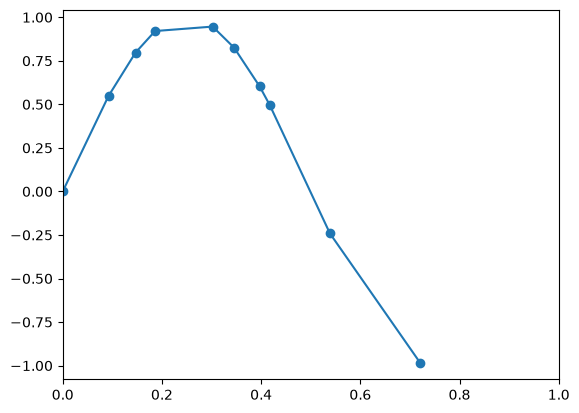

In [241]:
import os.path
import math
# Read in data from a file.  Download this from the BrightSpace  before you start.  
# If you forget to do this, the cell will generate the data for you, but small
# differences in random number generators might lead to different training data,
# which may make the lab harder to do.
filename = 'lab1_data.csv'

# If data doesn't exist, generate it
if not os.path.exists(filename):
    np.random.seed(1)
    train_x = np.sort(np.random.rand(10)) # 10 points, uniformly distributed between 0 and 1
    train_y = [math.sin(x * (2 * math.pi)) + 0.0 * np.random.randn() for x in train_x]
    data = np.transpose([train_x,train_y])
    np.savetxt(filename,data)

# Read in data from a file.  
data = np.loadtxt(filename)
train_x = np.asarray(data[:,0]).reshape((-1,1)) # First column of the data
train_y = np.asarray(data[:,1]).reshape((-1,1)) # Second column of the data
plt.xlim(0,1)
plt.plot(train_x, train_y,'o-')

Predictions with different kernels
Mean constant: 0, Length scale: 1.0, Output scale (alpha0): 1.0


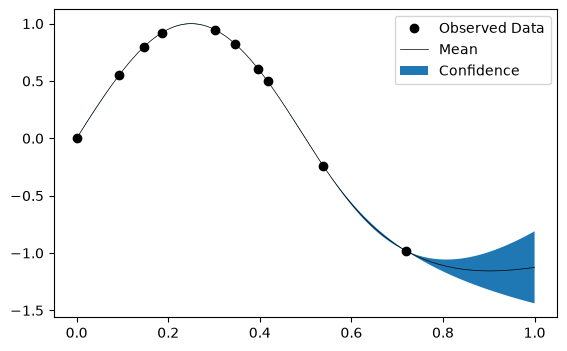

Mean constant: 0, Length scale: 0.05, Output scale (alpha0): 1.0


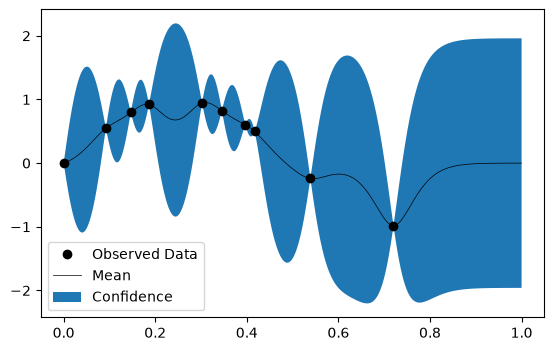

Mean constant: 0, Length scale: 0.05, Output scale (alpha0): 20.0


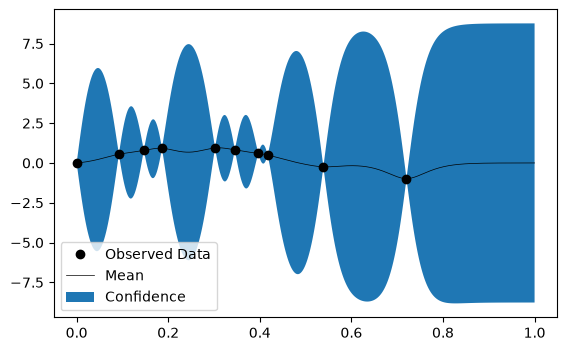

Mean constant: 0, Length scale: 1.0, Output scale (alpha0): 20.0


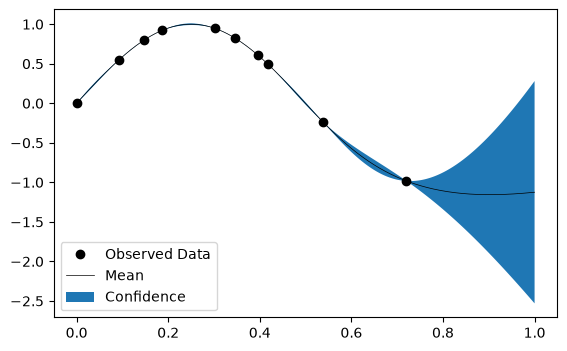

Mean constant: -0.5, Length scale: 1.0, Output scale (alpha0): 1.0


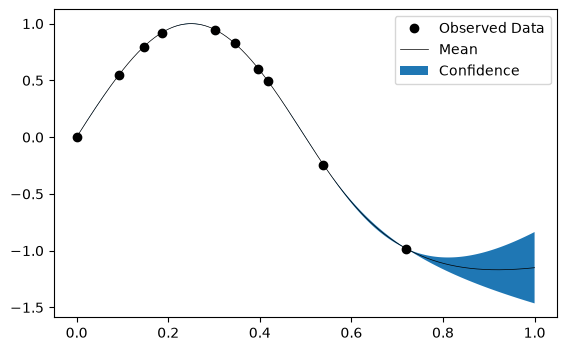

Mean constant: -2.852, Length scale: 1.305, Output scale (alpha0): 19.341


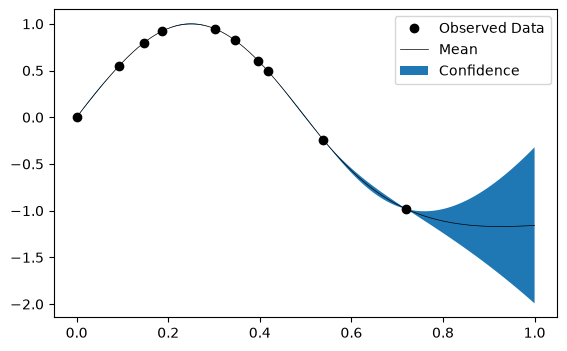

In [242]:

 # Once you have your predict function written, you can run the following code to plot your p
 # (the posterior mean), 95% Bayesian credible intervals (posterior mean +/- 1.96 * posterior
 # and the data


def plot_prediction(mean_:GPyTorchMean, kernel_:GPyTorchKernel):
    m = []
    lb = []
    ub = []
    x = np.linspace(0,1,1000)
    for test_x in x:
        mod_test_x = np.array(test_x).reshape((-1,1))
        pred_mean, pred_var = fit_predict(mod_test_x,train_x,train_y,kernel_,mean_)
        m.append(pred_mean)
       
        # Calculate the posterior standard deviation
        if pred_var<0.0:
            pred_var = 0.0
        
        s = np.sqrt(pred_var).ravel()[0] 
        lb.append((pred_mean-1.96*s))
        ub.append((pred_mean+1.96*s))

    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(train_x,train_y,'ko')
    ax.plot(x,np.asarray(m).reshape((-1,1)),'k',linewidth=0.5)
    ax.fill_between(x,np.asarray(lb).ravel(),np.asarray(ub).ravel())
    ax.legend(['Observed Data', 'Mean', 'Confidence'])

    plt.show()

# NOTE: You can change the kernel here to see how it affects the prediction   
# You can change the kernel parameters to get different kinds of fits.


constant_mean_array = [0,0,0,0,-0.5,-2.852]
alpha0_array = [1.0,1.0,20.0,20.0,1.0,19.341]
length_scale_array = [1.0,0.05,0.05,1.0,1.0,1.305]


# Plot the prediction
print("Predictions with different kernels")
# You can change the kernel parameters to get different kinds of fits.
# Here, we are increasing the value of alpha0 from the default of 1.
for i in range(len(constant_mean_array)):
    base_mean = ConstantMean()
    # Change the mean constant
    base_mean.constant = torch.tensor(constant_mean_array[i])
    # Change the kernel parameters

    base_kern = ScaleKernel(MaternKernel(nu=2.5))
    base_kern.base_kernel.lengthscale = torch.tensor(length_scale_array[i])
    # Change the outputscale (alpha0)
    base_kern.outputscale = torch.tensor(alpha0_array[i])
    print(f"Mean constant: {constant_mean_array[i]}, Length scale: {length_scale_array[i]}, Output scale (alpha0): {alpha0_array[i]}")
    plot_prediction(base_mean, base_kern)




### Exercise #4: Simulating Paths from Posterior
You can also use your code to simulate sample paths from a Gaussian process posterior with a given mean and kernel function. To do this, fill in the gaps in the following code. This will help show how different mean functions, kernels, and their hyperparameters influence the kinds of functions that are likely under the prior. This is important for choosing what mean function and kernel to use in an application.

1) Simulate from left to right (`i=0` up to `m-1`), storing the value of `f(x[i]) in y[i]` . For our first point `(i=0)`, simulate from the prior, whose mean is the mean function evaluated at `x[0]` , and variance is the kernel function evaluated with both inputs at `x[0]` . Use ` torch.distributions.Normal` for the normal distribution. Remember that it takes the standard devation as input, not the variance. (https://docs.pytorch.org/docs/main/distributions.html#normal)
2) For the other m-1 points, get the posterior distribution at the point `x[i+1]` in our input space given the observations we have simulated so far ( x and y , 0 through i, inclusive). Use your predict function to get its mean and variance

In [257]:
# Here for reproducibility, we set the random seed to a fixed value.
torch.manual_seed(0)

def simulate_from_prior(mean_: GPyTorchMean, kernel_: GPyTorchKernel, m=20):



  x = torch.linspace(0, 1, m, dtype=torch.double).reshape(-1, 1)
  y = torch.empty((m, 1), dtype=torch.double)

  # Draw the first value from its marginal prior distribution.
  mu0 = mean_(x[:1]).reshape(())
  var0 = kernel_(x[:1], x[:1]).to_dense().reshape(())
  y[0, 0] = torch.distributions.Normal(
      mu0, torch.sqrt(var0.clamp_min(0))
      ).sample()


  ##### TODO:  Enter your code here:

  # Draw each later value conditional on those already sampled.
  for i in range(1, m):
      pred_mean, pred_var = fit_predict(
          x[i:i + 1], x[:i], y[:i], kernel_, mean_
      )
      mu = torch.as_tensor(pred_mean).reshape(())
      var = torch.as_tensor(pred_var).reshape(())
      y[i, 0] = torch.distributions.Normal(
          mu, torch.sqrt(var.clamp_min(1e-12))
      ).sample()

  ### END OF CODE INPUT ###
  return x.numpy(), y.numpy()

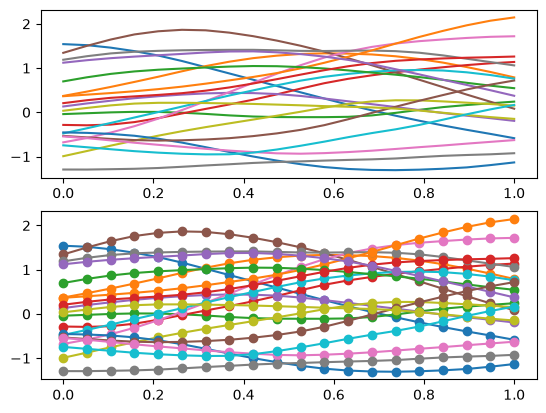

In [258]:

mean_module = ConstantMean()
kernel_module = ScaleKernel(MaternKernel(nu=2.5))

mean_module.constant = torch.tensor(0.0)

kernel_module.base_kernel.lengthscale = torch.tensor(1.0) #lengthscale
kernel_module.outputscale = torch.tensor(1.0) #alpha0

# Using this, we can simulate many different sample paths from the posterior

def simulate_many_from_prior(mean_: GPyTorchMean, kernel_: GPyTorchKernel, n=20, m=20):
   """Simulate many sample paths from the prior."""
   fig, ax = plt.subplots(2)
   for i in range(n):
     x,y = simulate_from_prior(mean_,kernel_,m)
     ax[0].plot(x,y)
     # The second figure shows the predicted value at each discretized point
     ax[1].plot(x,y, '-o')

simulate_many_from_prior(mean_module, kernel_module)

A similar approach can be implemented to simulate the posterior for a GP. `BoTorch` already implements this. We show an example of an example code to call now the posterior and generate samples. This approach is used for Monte-Carlo sampling methods (take a look at the Thompson Sampling acquisition).

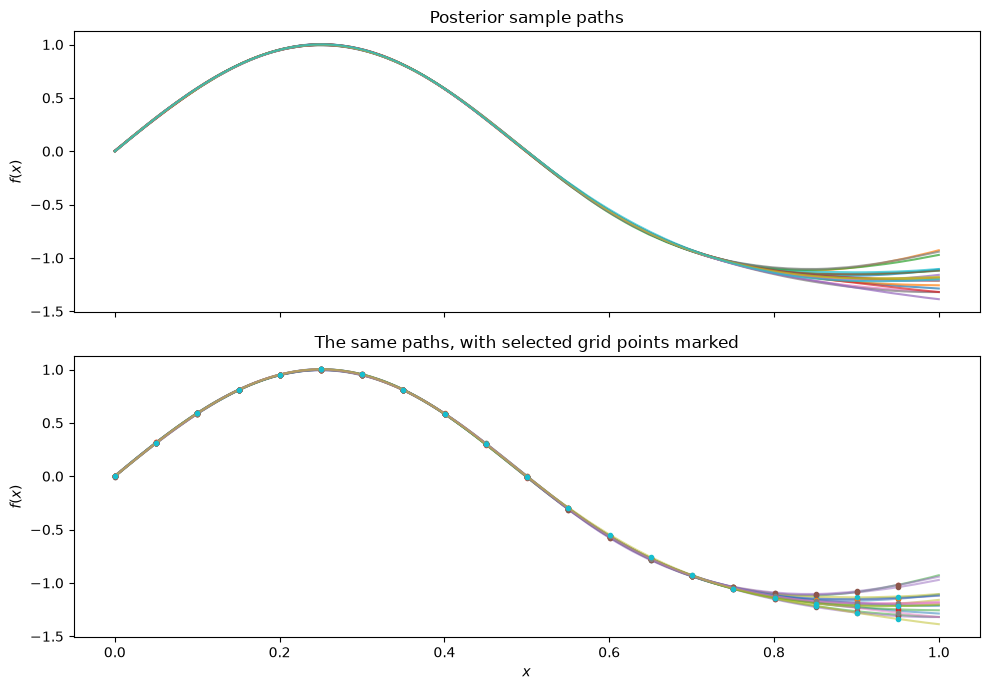

In [267]:
train_X = torch.as_tensor(train_x, dtype=torch.float64).reshape(-1, 1)
train_Y = torch.as_tensor(train_y, dtype=torch.float64).reshape(-1, 1)
train_Yvar = torch.full_like(train_Y, 1e-5)

mod_ = SingleTaskGP(
    train_X=train_X,
    train_Y=train_Y,
    train_Yvar=train_Yvar,
    covar_module=kernel_module,
    mean_module=mean_module,
    outcome_transform=Standardize(m=1),
).eval()


def simulate_many_from_posterior(model: SingleTaskGP, n: int = 20):
    """Plot n posterior sample paths and selected points on those paths."""
    x = torch.linspace(
        0, 1, 1000,
        dtype=model.train_inputs[0].dtype,
        device=model.train_inputs[0].device,
    ).unsqueeze(-1)

    with torch.no_grad():
        posterior = model.posterior(x)
        # Shape: (n samples, 1000 input points, 1 output)
        paths = posterior.rsample(sample_shape=torch.Size([n]))

    x_np = x.squeeze(-1).cpu().numpy()
    paths_np = paths.squeeze(-1).cpu().numpy()
    marked = slice(None, None, 50)

    fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    for path in paths_np:
        ax[0].plot(x_np, path, alpha=0.7)
        ax[1].plot(x_np, path, alpha=0.5)
        ax[1].plot(x_np[marked], path[marked], "o", markersize=3)

    ax[0].set_title("Posterior sample paths")
    ax[1].set_title("The same paths, with selected grid points marked")
    ax[1].set_xlabel("$x$")
    ax[0].set_ylabel("$f(x)$")
    ax[1].set_ylabel("$f(x)$")
    fig.tight_layout()
    plt.show()


simulate_many_from_posterior(mod_)

### Exercise #5:
Play around with the parameters of the constant mean and matern kernel to understand how they influence the predictions and the simulated sample paths. In the following code, copied from above, we see 3 parameters: the mean of the constant mean, and the `alpha_0`, `length_scale` (which is a scalar when we have 1-dimensional x), and `nu`. With the implementation before, you could also use other types of kernels currently implemented within the `GPyTorch` framework.